
# Beyond Accuracy: Evaluating Credit Risk Models Through Financial Decision-Making

**Stephanie Nord · Applied Data Science portfolio**

## Run the notebook

Use Python 3.12 and install the packages listed in `requirements.txt`.
Open this notebook in JupyterLab, select the Python 3 kernel, and run all cells
from top to bottom. The first cell downloads the [UCI Default of Credit Card
Clients dataset](https://doi.org/10.24432/C55S3H). Figures and summary tables
are written to the `figures/` directory and the data dictionary to `data/`.

## Project Overview

This project examines the predictive performance and practical implications of credit card default risk models using historical financial data. Logistic regression and random forest are compared using classification metrics, probability calibration, and hypothetical financial decision costs.

The analysis investigates whether model accuracy alone provides sufficient information for credit risk decision-making and considers the ethical implications, limitations, and potential applications of the results.

### Research Questions

1. How do logistic regression and random forest compare in predicting next-month credit card default?
2. How well calibrated are the predicted default probabilities generated by each model?
3. How do classification thresholds influence false-positive and false-negative rates under different hypothetical financial cost assumptions?

## Dataset Retrieval and Initial Inspection

In [1]:
from pathlib import Path

from ucimlrepo import fetch_ucirepo
import pandas as pd

credit = fetch_ucirepo(id=350)

X = credit.data.features.copy()
y = credit.data.targets.copy()

print("Features:", X.shape)
print("Target:", y.shape)

display(X.head())
display(y.value_counts())

display(credit.variables)

from pathlib import Path

Path("data").mkdir(exist_ok=True)

X.to_csv("data/credit_features.csv", index=False)
y.to_csv("data/credit_target.csv", index=False)

Features: (30000, 23)
Target: (30000, 1)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


Y
0    23364
1     6636
Name: count, dtype: int64

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,None,None,no
1,X1,Feature,Integer,None,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,None,PAY_0,None,no
7,X7,Feature,Integer,None,PAY_2,None,no
8,X8,Feature,Integer,None,PAY_3,None,no
9,X9,Feature,Integer,None,PAY_4,None,no


In [2]:
# Check missing values, duplicates, and variable types

print("Dataset dimensions:", X.shape)

print("\nMissing values:")
display(X.isna().sum().sort_values(ascending=False))

print("\nDuplicate predictor rows:", X.duplicated().sum())

print("\nData types:")
display(X.dtypes.value_counts())

print("\nSummary statistics:")
display(X.describe().T)

Dataset dimensions: (30000, 23)

Missing values:


X1     0
X2     0
X3     0
X4     0
X5     0
X6     0
X7     0
X8     0
X9     0
X10    0
X11    0
X12    0
X13    0
X14    0
X15    0
X16    0
X17    0
X18    0
X19    0
X20    0
X21    0
X22    0
X23    0
dtype: int64


Duplicate predictor rows: 56

Data types:


int64    23
Name: count, dtype: int64


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
X1,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
X2,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
X3,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
X4,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
X5,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
X6,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
X7,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
X8,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
X9,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
X10,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


### Data Dictionary and Variable Definitions

In [3]:

# Create a data dictionary from the original UCI metadata

# Map original UCI columns to descriptive names
column_names = {
    "ID": "ID",
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6",
    "Y": "DEFAULT"
}

# Descriptions based on the UCI dataset documentation
# and observed coding limitations

descriptions = {
    "ID": "Record identifier; excluded from modeling",
    "LIMIT_BAL": "Credit limit in New Taiwan dollars (NTD)",
    "SEX": "Recorded sex: 1 = male, 2 = female",
    "EDUCATION": (
        "Education: 1 = graduate school, "
        "2 = university, 3 = high school, "
        "4 = other; codes 0, 5, and 6 undocumented"
    ),
    "MARRIAGE": (
        "Marital status: 1 = married, "
        "2 = single, 3 = other; code 0 undocumented"
    ),
    "AGE": "Customer age in years",
    "PAY_0": "Repayment status, September 2005",
    "PAY_2": "Repayment status, August 2005",
    "PAY_3": "Repayment status, July 2005",
    "PAY_4": "Repayment status, June 2005",
    "PAY_5": "Repayment status, May 2005",
    "PAY_6": "Repayment status, April 2005",
    "DEFAULT": "Next-month default: 0 = no, 1 = yes"
}

# Monthly financial variables
months = [
    "September", "August", "July",
    "June", "May", "April"
]

for i, month in enumerate(months, start=1):
    descriptions[f"BILL_AMT{i}"] = (
        f"Bill statement amount, {month} 2005 (NTD)"
    )
    descriptions[f"PAY_AMT{i}"] = (
        f"Previous payment amount, {month} 2005 (NTD)"
    )

# Retrieve original UCI metadata
data_dictionary = credit.variables.copy()

# Map descriptive variable names
data_dictionary["Descriptive_Name"] = (
    data_dictionary["name"].map(column_names)
)

# Add explanatory descriptions
data_dictionary["Variable_Description"] = (
    data_dictionary["Descriptive_Name"].map(descriptions)
)

# Select dictionary columns
data_dictionary = data_dictionary[
    [
        "name",
        "Descriptive_Name",
        "role",
        "type",
        "demographic",
        "Variable_Description",
        "missing_values"
    ]
].copy()

# Rename columns for readability
data_dictionary.columns = [
    "Original_Name",
    "Descriptive_Name",
    "Role",
    "Data_Type",
    "Demographic_Category",
    "Description",
    "Missing_Values"
]

# Verify every variable has a definition
assert data_dictionary["Descriptive_Name"].notna().all(), (
    "Some UCI variables are missing name mappings."
)

assert data_dictionary["Description"].notna().all(), (
    "Some variables are missing descriptions."
)

# Display the completed data dictionary
display(data_dictionary)

# Export for reproducibility and report appendix
Path("data").mkdir(exist_ok=True)

data_dictionary.to_csv(
    "data/credit_risk_data_dictionary.csv",
    index=False
)

print(
    f"Data dictionary saved successfully: "
    f"{len(data_dictionary)} variables documented."
)

,Original_Name,Descriptive_Name,Role,Data_Type,Demographic_Category,Description,Missing_Values
0,ID,ID,ID,Integer,None,Record identifier; excluded from modeling,no
1,X1,LIMIT_BAL,Feature,Integer,None,Credit limit in New Taiwan dollars (NTD),no
2,X2,SEX,Feature,Integer,Sex,"Recorded sex: 1 = male, 2 = female",no
3,X3,EDUCATION,Feature,Integer,Education Level,"Education: 1 = graduate school, 2 = university...",no
4,X4,MARRIAGE,Feature,Integer,Marital Status,"Marital status: 1 = married, 2 = single, 3 = o...",no
5,X5,AGE,Feature,Integer,Age,Customer age in years,no
6,X6,PAY_0,Feature,Integer,None,"Repayment status, September 2005",no
7,X7,PAY_2,Feature,Integer,None,"Repayment status, August 2005",no
8,X8,PAY_3,Feature,Integer,None,"Repayment status, July 2005",no
9,X9,PAY_4,Feature,Integer,None,"Repayment status, June 2005",no


Data dictionary saved successfully: 25 variables documented.


### Data Dictionary Notes and Coding Limitations

The original dataset uses X1–X23 for the predictors and
Y for the binary default outcome. Descriptive names were
assigned to improve readability without changing the
underlying observations.

Credit limits, billing amounts, and payment amounts are
reported in New Taiwan dollars (NTD).

The six repayment-status variables represent monthly
observations from April through September 2005. The
documented status scale includes -1 for payment made
on time and positive values indicating months of delay.
However, the dataset also contains -2 and 0, whose
meanings are not established by the original source
documentation.

EDUCATION includes codes 0, 5, and 6, while MARRIAGE
includes code 0. These values were retained rather than
assigned unsupported labels.

Minimum and maximum values describe the observed
data distributions and do not necessarily represent
valid boundaries or meaningful numerical scales for
categorical variables.

Source: Yeh (2009), UCI Machine Learning Repository.

## Variable Interpretation and Categorical Value Assessment

In [4]:
# Rename predictors using the UCI data dictionary

X_named = X.rename(columns=column_names)

# Examine all observed categorical codes
categorical_columns = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

for column in categorical_columns:
    print(f"\n{column}")
    display(
        X_named[column]
        .value_counts(dropna=False)
        .sort_index()
        .rename("Count")
        .to_frame()
    )


SEX


,Count
SEX,
1,11888
2,18112



EDUCATION


,Count
EDUCATION,
0,14
1,10585
2,14030
3,4917
4,123
5,280
6,51



MARRIAGE


,Count
MARRIAGE,
0,54
1,13659
2,15964
3,323


... (8 outputs left out)


PAY_5


,Count
PAY_5,
-2,4546
-1,5539
0,16947
2,2626
3,178
4,84
5,17
6,4
7,58



PAY_6


,Count
PAY_6,
-2,4895
-1,5740
0,16286
2,2766
3,184
4,49
5,13
6,19
7,46


### Initial Data Quality Findings

The dataset contains 30,000 observations and 23 predictor variables. An initial inspection found no missing values, and all predictor variables were stored as integers. However, the data types alone do not establish whether the features should be treated as continuous measurements or categorical variables.

The duplicate-row assessment identified 56 repeated predictor combinations. These records will be investigated further rather than automatically removed because identical predictors do not necessarily indicate duplicate customer records.

Summary statistics also identified negative billing amounts and repayment-status codes requiring further examination. These values will be evaluated against the source documentation before any transformations are performed.

This initial assessment establishes the need to distinguish valid financial observations, encoded categories, and potential data-quality problems before developing the classification models.

## Exploratory Analysis: Default Rates Across Customer Groups

In [5]:
# Combine predictors and target for exploratory analysis

eda_df = X_named.copy()
eda_df["DEFAULT"] = y.iloc[:, 0].to_numpy()

# Compare default outcomes by recorded sex
sex_default = (
    eda_df.groupby("SEX")["DEFAULT"]
    .agg(
        Customers="count",
        Defaults="sum",
        Default_Rate="mean"
    )
)

sex_default["Default_Rate"] *= 100

display(sex_default.round(2))

,Customers,Defaults,Default_Rate
SEX,,,
1,11888,2873,24.17
2,18112,3763,20.78


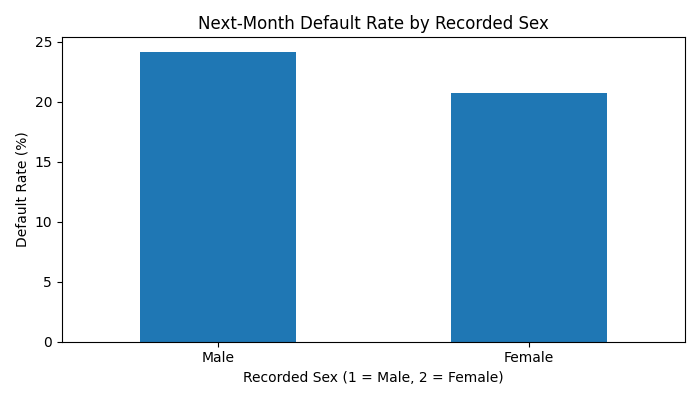

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

sex_default["Default_Rate"].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Next-Month Default Rate by Recorded Sex")
ax.set_xlabel("Recorded Sex (1 = Male, 2 = Female)")
ax.set_ylabel("Default Rate (%)")
ax.set_xticklabels(["Male", "Female"], rotation=0)

plt.tight_layout()
plt.show()

In [7]:
pay0_default = (
    eda_df.groupby("PAY_0")["DEFAULT"]
    .agg(
        Customers="count",
        Defaults="sum",
        Default_Rate="mean"
    )
)

pay0_default["Default_Rate"] *= 100

display(pay0_default.round(2))

,Customers,Defaults,Default_Rate
PAY_0,,,
-2,2759,365,13.23
-1,5686,954,16.78
0,14737,1888,12.81
1,3688,1252,33.95
2,2667,1844,69.14
3,322,244,75.78
4,76,52,68.42
5,26,13,50.00
6,11,6,54.55


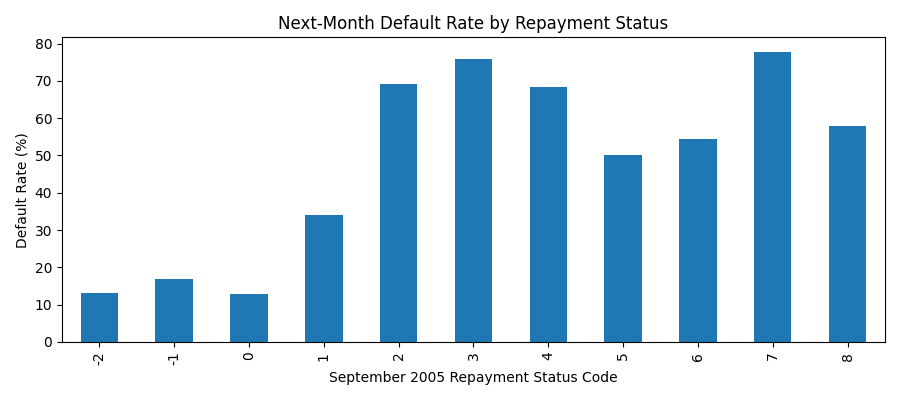

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))

pay0_default["Default_Rate"].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Next-Month Default Rate by Repayment Status")
ax.set_xlabel("September 2005 Repayment Status Code")
ax.set_ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

## Data Preparation and Validation Design

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

Path("figures").mkdir(exist_ok=True)

# Use the renamed predictors from earlier EDA
X_model = X_named.copy()
y_model = y.iloc[:, 0].astype(int).copy()

# Treat nominal and repayment codes as categorical.
# Preserve undocumented values as distinct codes.
categorical = categorical_columns

numeric = [
    col for col in X_model.columns
    if col not in categorical
]

# 60% training, 20% validation, 20% held-out test
X_dev, X_test, y_dev, y_test = train_test_split(
    X_model, y_model,
    test_size=0.20,
    stratify=y_model,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nDefault rates:")
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(name, round(target.mean() * 100, 2), "%")

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical)
])

Training: (18000, 23)
Validation: (6000, 23)
Test: (6000, 23)

Default rates:
Train 22.12 %
Validation 22.12 %
Test 22.12 %


## Model Development and Validation

In [10]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    accuracy_score
)

models = {
    "Logistic Regression": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=120,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=42
        ))
    ])
}

validation_results = []
val_probabilities = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]
    val_probabilities[name] = probabilities

    validation_results.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "Average_Precision": average_precision_score(
            y_val, probabilities
        ),
        "Brier_Score": brier_score_loss(
            y_val, probabilities
        ),
        "Accuracy_0.50": accuracy_score(
            y_val, probabilities >= 0.50
        )
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))

# Select using average precision on validation data
best_name = validation_df.sort_values(
    "Average_Precision", ascending=False
).iloc[0]["Model"]

print("\nSelected model:", best_name)

Training Logistic Regression...
Training Random Forest...


,Model,ROC_AUC,Average_Precision,Brier_Score,Accuracy_0.50
0,Logistic Regression,0.7629,0.5372,0.1368,0.8207
1,Random Forest,0.7846,0.5498,0.1343,0.8188



Selected model: Random Forest


### Model Selection and Validation Interpretation

Logistic regression and random forest were selected to compare a conventional, interpretable classification method with a model capable of capturing nonlinear relationships and interactions among predictors. More complex methods were not included because the analysis prioritizes reproducibility, interpretability, and a focused comparison of predictive performance.

Both models were trained using the same 18,000 observations and evaluated on a separate validation set of 6,000 observations. The preprocessing pipeline was fitted using training data to reduce information leakage.

The random forest achieved a higher ROC-AUC (0.7846) than logistic regression (0.7629), indicating somewhat better discrimination between customers who defaulted and those who did not. Random forest also achieved higher average precision (0.5498 versus 0.5372) and a slightly lower Brier score (0.1343 versus 0.1368), suggesting better performance in ranking default cases and estimating default probabilities on this validation set.

However, logistic regression achieved slightly higher accuracy at the conventional 0.50 classification threshold (82.07% versus 81.88%). This illustrates why accuracy alone may not be sufficient for evaluating credit risk models, particularly when incorrectly identifying or overlooking defaults can have different consequences.

Random forest was selected for further analysis based on its higher validation average precision. This selection was made before evaluating the held-out test set to avoid using test results to influence model selection.


## Held-Out Test Evaluation

,Model,ROC_AUC,Average_Precision,Brier_Score,Precision,Recall,Accuracy
0,Logistic Regression,0.7591,0.5258,0.1388,0.6662,0.3519,0.8177
1,Random Forest,0.7704,0.5511,0.1361,0.6623,0.3444,0.8162



Selected model classification report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.34      0.45      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.67      6000
weighted avg       0.80      0.82      0.79      6000



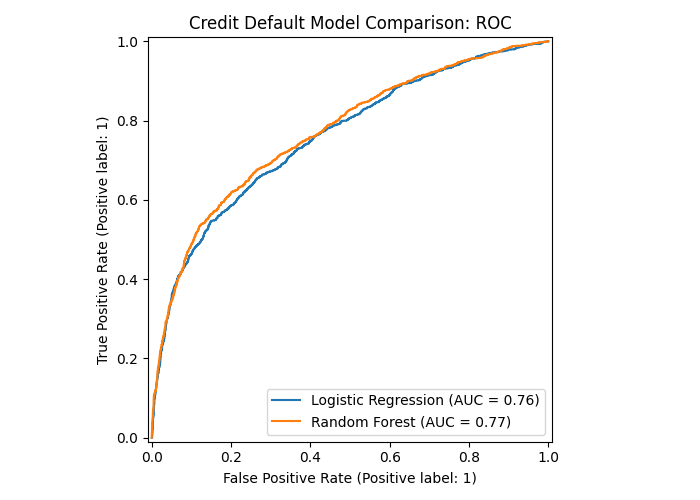

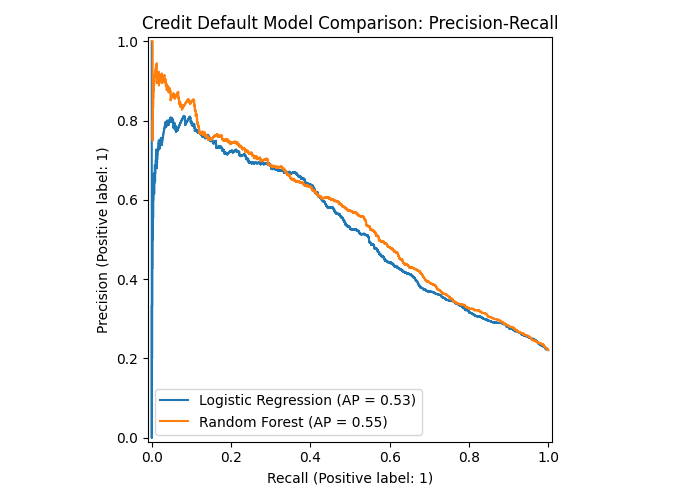

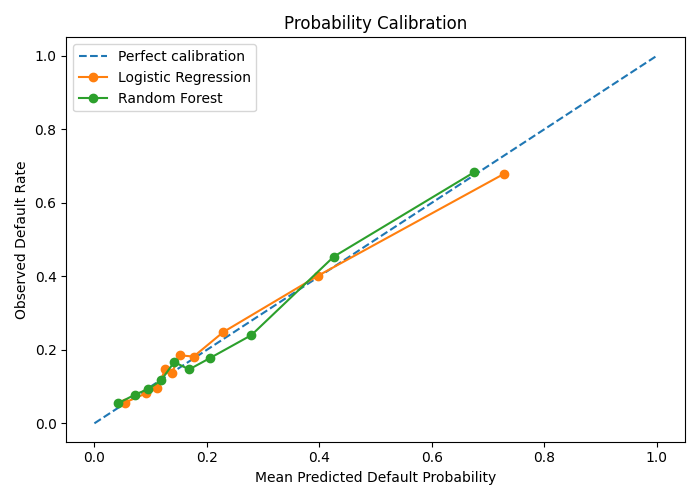

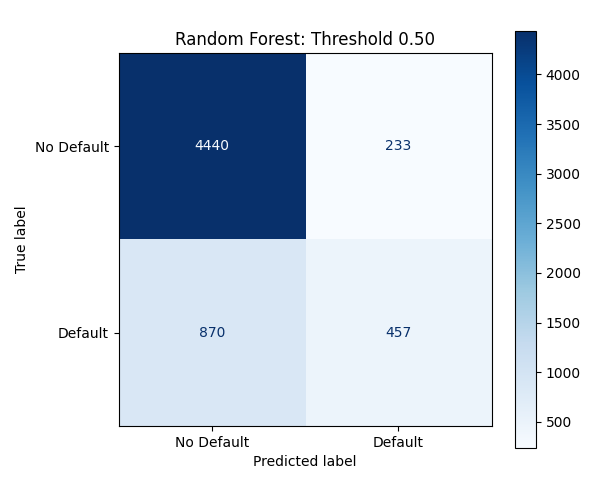

In [11]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.calibration import calibration_curve

test_probabilities = {}
test_results = []

for name, model in models.items():

    probs = model.predict_proba(X_test)[:, 1]
    test_probabilities[name] = probs

    predictions = (probs >= 0.50).astype(int)

    test_results.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y_test, probs),
        "Average_Precision": average_precision_score(
            y_test, probs
        ),
        "Brier_Score": brier_score_loss(
            y_test, probs
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Accuracy": accuracy_score(y_test, predictions)
    })

test_df = pd.DataFrame(test_results)
display(test_df.round(4))

print("\nSelected model classification report:")
selected_probs = test_probabilities[best_name]

print(classification_report(
    y_test,
    selected_probs >= 0.50,
    zero_division=0
))

# Figure 1: ROC curves
fig, ax = plt.subplots(figsize=(7, 5))

for name, probs in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, probs, name=name, ax=ax
    )

ax.set_title("Credit Default Model Comparison: ROC")
plt.tight_layout()
fig.savefig("figures/01_roc_comparison.png", dpi=300)
plt.show()

# Figure 2: Precision-recall curves
fig, ax = plt.subplots(figsize=(7, 5))

for name, probs in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test, probs, name=name, ax=ax
    )

ax.set_title("Credit Default Model Comparison: Precision-Recall")
plt.tight_layout()
fig.savefig("figures/02_precision_recall.png", dpi=300)
plt.show()

# Figure 3: Calibration
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    [0, 1], [0, 1], "--",
    label="Perfect calibration"
)

for name, probs in test_probabilities.items():
    observed, predicted = calibration_curve(
        y_test, probs,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        predicted, observed,
        marker="o", label=name
    )

ax.set_xlabel("Mean Predicted Default Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("Probability Calibration")
ax.legend()

plt.tight_layout()
fig.savefig("figures/03_calibration.png", dpi=300)
plt.show()

# Figure 4: Confusion matrix at the default threshold
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    (selected_probs >= 0.50).astype(int),
    display_labels=["No Default", "Default"],
    ax=ax,
    cmap="Blues"
)

ax.set_title(f"{best_name}: Threshold 0.50")
plt.tight_layout()
fig.savefig("figures/04_confusion_matrix.png", dpi=300)
plt.show()


### Held-Out Test Results and Interpretation

The two models were evaluated on the same held-out test set of 6,000 customer records. Random forest achieved a ROC-AUC of 0.7704, compared with 0.7591 for logistic regression. The ROC curves show that random forest demonstrated slightly stronger discrimination between customers who defaulted and those who did not, although the performance difference was relatively small.

The precision–recall curves provide additional information about model performance on the less frequent default class, which represented approximately 22.12% of the dataset. Random forest achieved an average precision of 0.5511, compared with 0.5258 for logistic regression. Both results exceeded the default prevalence baseline, indicating that the models provided useful discrimination beyond random ranking.

Probability calibration was evaluated using calibration curves and Brier scores. Both models generally followed the ideal calibration reference, although some deviations were visible. Random forest achieved a slightly lower Brier score of 0.1361 compared with 0.1388 for logistic regression, indicating lower average squared probability error on the test set. However, neither model demonstrated perfect calibration, and the differences do not establish that additional calibration would improve operational performance.

The confusion matrix reveals an important limitation of the selected random forest model. At the conventional 0.50 classification threshold, it correctly identified 457 of 1,327 customers who experienced default but failed to identify 870. This corresponds to a default-class recall of approximately 34.44%, meaning that roughly 65.56% of actual defaults were missed.

Despite this limitation, random forest achieved an overall accuracy of 81.62%. The difference between accuracy and recall demonstrates why classification accuracy alone may provide an incomplete picture of credit risk model performance. Most customers in the dataset did not default, allowing the model to achieve relatively high accuracy while overlooking many cases of financial risk.

These findings support further investigation of classification thresholds and the relative consequences of false-positive and false-negative predictions.


## Decision Thresholds and Hypothetical Financial Costs

In [12]:
# Hypothetical cost assumptions:
# False positive = $100
# False negative = $100, $300, or $500

scenarios = {
    "Equal costs": (100, 100),
    "3:1 missed-default cost": (100, 300),
    "5:1 missed-default cost": (100, 500)
}

thresholds = np.arange(0.05, 0.951, 0.01)

def decision_cost(y_true, probs, threshold, fp_cost, fn_cost):
    predictions = probs >= threshold
    y_array = np.asarray(y_true)

    fp = np.sum((predictions == 1) & (y_array == 0))
    fn = np.sum((predictions == 0) & (y_array == 1))

    total_cost = fp * fp_cost + fn * fn_cost

    return total_cost, fp, fn


cost_results = []
validation_cost_curves = {}

for scenario, (fp_cost, fn_cost) in scenarios.items():

    validation_costs = [
        decision_cost(
            y_val,
            val_probabilities[best_name],
            t,
            fp_cost,
            fn_cost
        )[0]
        for t in thresholds
    ]

    optimal_index = np.argmin(validation_costs)
    selected_threshold = thresholds[optimal_index]

    # Evaluate the validation-selected threshold on test data
    test_cost, fp, fn = decision_cost(
        y_test,
        selected_probs,
        selected_threshold,
        fp_cost,
        fn_cost
    )

    cost_results.append({
        "Scenario": scenario,
        "Selected_Threshold": selected_threshold,
        "False_Positives": fp,
        "False_Negatives": fn,
        "Test_Cost": test_cost,
        "Cost_per_1000": test_cost / len(y_test) * 1000
    })

    validation_cost_curves[scenario] = np.asarray(validation_costs) / len(y_val) * 1000

cost_df = pd.DataFrame(cost_results)

display(cost_df.round(2))

,Scenario,Selected_Threshold,False_Positives,False_Negatives,Test_Cost,Cost_per_1000
0,Equal costs,0.45,293,812,110500,18416.67
1,3:1 missed-default cost,0.29,681,585,243600,40600.00
2,5:1 missed-default cost,0.17,1685,356,346500,57750.00


## Financial Decision Analysis

Thresholds were selected on the validation set and evaluated on the held-out test set. The dots show the minimum estimated cost within each validation scenario.

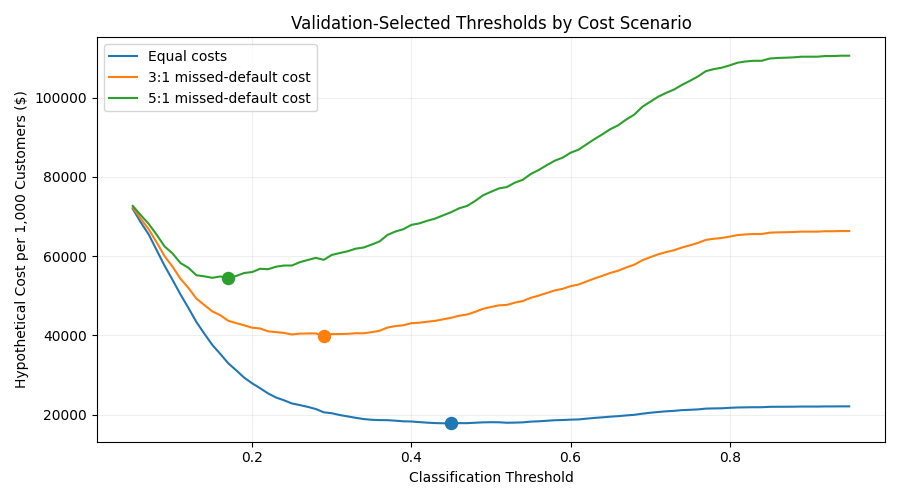

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

for scenario, costs in validation_cost_curves.items():

    selected_t = cost_df.loc[
        cost_df["Scenario"] == scenario,
        "Selected_Threshold"
    ].iloc[0]

    ax.plot(
        thresholds,
        costs,
        label=scenario
    )

    selected_cost = costs[np.argmin(costs)]

    ax.scatter(
        selected_t,
        selected_cost,
        color=ax.lines[-1].get_color(),
        s=75,
        zorder=5
    )

ax.set_title(
    "Validation-Selected Thresholds by Cost Scenario"
)
ax.set_xlabel("Classification Threshold")
ax.set_ylabel(
    "Hypothetical Cost per 1,000 Customers ($)"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    "figures/05_financial_cost_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Financial Decision-Cost Interpretation

The financial decision analysis examined how different classification thresholds affect the consequences of false-positive and false-negative predictions. Three hypothetical cost scenarios were evaluated, assigning a false-positive cost of 100 dollars and false-negative costs of 100, 300, or 500 dollars.

Thresholds were selected using validation data and subsequently evaluated on the held-out test set. Under equal error costs, the selected threshold was 0.45, resulting in 293 false positives and 812 false negatives. When missed defaults were assumed to cost three times as much as false positives, the selected threshold decreased to 0.29, producing 681 false positives and 585 false negatives. Under the five-to-one scenario, the threshold decreased further to 0.17, with 1,685 false positives and 356 false negatives.

These findings demonstrate that reducing the classification threshold identifies more customers who subsequently default but also incorrectly flags more customers who do not default. The preferred threshold therefore depends on the relative consequences assigned to different prediction errors rather than model accuracy alone.

The validation cost curves show how each scenario’s estimated cost changes across the threshold grid. Because the financial penalties are hypothetical, the results should not be interpreted as actual bank losses or demonstrated financial savings. Costs across scenarios are not directly comparable because each scenario uses different assumptions.

The analysis answers the third research question by demonstrating that classification thresholds substantially affect both the distribution of errors and the estimated consequences of credit risk decisions. Any operational implementation would require observed financial loss information, updated customer data, and additional validation before a classification threshold could be recommended.


## Ethical Assessment: Model Performance Across Demographic Groups

In [14]:
# Predictions from the selected model
test_predictions = (selected_probs >= 0.50).astype(int)

fairness_results = []

for code, label in [(1, "Male"), (2, "Female")]:
    mask = X_test["SEX"].to_numpy() == code

    actual = y_test.to_numpy()[mask]
    predicted = test_predictions[mask]

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    fairness_results.append({
        "Group": label,
        "Customers": len(actual),
        "Observed_Default_Rate": actual.mean(),
        "False_Positive_Rate": fp / (fp + tn),
        "False_Negative_Rate": fn / (fn + tp),
        "Recall": tp / (tp + fn)
    })

fairness_df = pd.DataFrame(fairness_results)

display(fairness_df.round(4))


,Group,Customers,Observed_Default_Rate,False_Positive_Rate,False_Negative_Rate,Recall
0,Male,2402,0.2336,0.0521,0.6649,0.3351
1,Female,3598,0.2129,0.0484,0.6488,0.3512


### Fairness Assessment and Ethical Implications

An initial fairness assessment compared the selected random forest model's performance across the recorded male and female customer groups. The analysis used the held-out test set and the conventional 0.50 classification threshold.

The observed default rate was 23.36% among male customers and 21.29% among female customers. The false-positive rate was 5.21% for male customers and 4.84% for female customers, indicating that male customers were incorrectly classified as likely to default slightly more frequently among those who did not default.

The false-negative rate was 66.49% for male customers and 64.88% for female customers. These results indicate that the model failed to identify a substantial proportion of actual defaults in both groups. Although the differences between the groups were relatively small, the high false-negative rates raise concerns about the model's usefulness when identifying potential default risk.

These results do not establish that the model is fair or discriminatory. Differences in repayment histories, credit limits, and other characteristics could contribute to the observed outcomes. The dataset also represents Taiwanese customers from 2005, limiting the relevance of these findings to contemporary lending populations.

**Risk assessment and mitigation:** Disparate classification errors represent a potential high-impact concern with an initially assessed medium likelihood. The subgroup comparison provides a preliminary assessment, but additional fairness testing, confidence intervals, and evaluation across other demographic groups would be required before any operational use. The model should not be used to automate lending decisions based on these preliminary results.

## Data Integrity: Duplicate Predictor Patterns

In [15]:
# Inspect repeated predictor combinations
print("Repeated predictor rows in full dataset:")
print(X_model.duplicated().sum())

# Create comparable row signatures
train_hash = set(
    pd.util.hash_pandas_object(
        X_train, index=False
    ).to_numpy()
)

val_hash = set(
    pd.util.hash_pandas_object(
        X_val, index=False
    ).to_numpy()
)

test_hash = set(
    pd.util.hash_pandas_object(
        X_test, index=False
    ).to_numpy()
)

overlap_results = pd.DataFrame({
    "Comparison": [
        "Train vs Validation",
        "Train vs Test",
        "Validation vs Test"
    ],
    "Matching_Patterns": [
        len(train_hash & val_hash),
        len(train_hash & test_hash),
        len(val_hash & test_hash)
    ]
})

display(overlap_results)


Repeated predictor rows in full dataset:
56


,Comparison,Matching_Patterns
0,Train vs Validation,14
1,Train vs Test,11
2,Validation vs Test,5



### Duplicate-Pattern Assessment and Limitations

The initial data-quality assessment identified 56 repeated predictor rows among the 30,000 customer records. Because identical financial characteristics do not necessarily represent the same customer, these observations were retained rather than automatically removed.

A subsequent comparison examined identical predictor combinations across the training, validation, and test partitions. The analysis identified 14 matching patterns between training and validation, 11 between training and test, and five between validation and test.

These findings indicate that some identical feature combinations appear in multiple partitions. Although this does not establish duplicated customer identities, it raises a potential concern about the independence of observations used for model evaluation. If matching records represent repeated observations of the same individual, predictive performance could be somewhat overestimated.

**Risk assessment and mitigation:** Potential overlap between data partitions was assessed as a data-validity limitation. The overlap was documented rather than concealed, and no observations were removed without evidence that they represented duplicate customer records. Future analyses could investigate grouping or deduplication strategies when reliable customer identifiers are available.

The present evaluation therefore reflects model performance on the selected historical dataset and should not be interpreted as evidence of generalization to independent future lending populations.


## Final Results Summary and Reproducibility

In [16]:
# Export all final analysis tables
outputs = {
    "model_validation.csv": validation_df,
    "model_test_results.csv": test_df,
    "decision_cost_results.csv": cost_df,
    "fairness_assessment.csv": fairness_df,
    "duplicate_overlap_check.csv": overlap_results
}

for filename, table in outputs.items():
    table.to_csv(
        Path("figures") / filename,
        index=False
    )

print("FINAL PROJECT SUMMARY")
print("=" * 45)

print(f"Original observations: {len(X_model):,}")
print(f"Training observations: {len(X_train):,}")
print(f"Validation observations: {len(X_val):,}")
print(f"Test observations: {len(X_test):,}")
print(f"Selected model: {best_name}")

print("\nModel performance:")
display(test_df.round(4))

print("\nFinancial scenarios:")
display(cost_df.round(2))

print("\nFairness audit:")
display(fairness_df.round(4))

print("\nDuplicate overlap:")
display(overlap_results)

print("\nSaved figures:")
for file in sorted(Path("figures").glob("*.png")):
    print(file.name)

print("\nAnalysis exports completed.")

FINAL PROJECT SUMMARY
Original observations: 30,000
Training observations: 18,000
Validation observations: 6,000
Test observations: 6,000
Selected model: Random Forest

Model performance:


,Model,ROC_AUC,Average_Precision,Brier_Score,Precision,Recall,Accuracy
0,Logistic Regression,0.7591,0.5258,0.1388,0.6662,0.3519,0.8177
1,Random Forest,0.7704,0.5511,0.1361,0.6623,0.3444,0.8162



Financial scenarios:


,Scenario,Selected_Threshold,False_Positives,False_Negatives,Test_Cost,Cost_per_1000
0,Equal costs,0.45,293,812,110500,18416.67
1,3:1 missed-default cost,0.29,681,585,243600,40600.00
2,5:1 missed-default cost,0.17,1685,356,346500,57750.00



Fairness audit:


,Group,Customers,Observed_Default_Rate,False_Positive_Rate,False_Negative_Rate,Recall
0,Male,2402,0.2336,0.0521,0.6649,0.3351
1,Female,3598,0.2129,0.0484,0.6488,0.3512



Duplicate overlap:


,Comparison,Matching_Patterns
0,Train vs Validation,14
1,Train vs Test,11
2,Validation vs Test,5



Saved figures:
01_roc_comparison.png
02_precision_recall.png
03_calibration.png
04_confusion_matrix.png
05_financial_cost_sensitivity.png

Analysis exports completed.



## Final Conclusion, Recommendations, and Future Applications

### Conclusion

This project examined whether classification accuracy alone provides sufficient information for evaluating credit card default risk. Using 30,000 historical customer records, logistic regression and random forest were compared through discrimination metrics, probability calibration, and hypothetical financial decision costs.

The results address all three research questions:

1. **Model comparison:** Random forest achieved slightly higher ROC-AUC (0.7704) and average precision (0.5511) than logistic regression (0.7591 and 0.5258). However, logistic regression achieved marginally higher accuracy and recall at the 0.50 classification threshold.

2. **Probability calibration:** Both models demonstrated reasonably close agreement between predicted probabilities and observed default frequencies in the calibration plots. Random forest achieved a slightly lower Brier score (0.1361 versus 0.1388), although neither model demonstrated perfect calibration.

3. **Financial decision thresholds:** Changing the assumed relative costs of false-positive and false-negative predictions substantially affected the selected classification threshold. Lower thresholds reduced missed defaults but increased the number of customers incorrectly flagged as likely to default.

The findings support the conclusion that accuracy alone does not adequately describe a credit risk model's usefulness. The appropriate evaluation depends on probability reliability, classification errors, and the consequences of acting on predictions.

### Recommendations

Financial institutions evaluating similar models should consider multiple performance measures rather than relying exclusively on accuracy. Particular attention should be given to recall, precision, probability calibration, and the consequences of false-positive and false-negative predictions.

Classification thresholds should be selected using validation data and realistic financial cost estimates rather than accepting the conventional 0.50 threshold without evaluation.

The present models should not be used for operational lending decisions. Their performance was evaluated using historical Taiwanese data, and the financial cost scenarios were hypothetical. Additional validation, demographic fairness assessments, and consideration of applicable lending regulations would be necessary before practical application.

### Implementation Plan

A potential implementation would begin by collecting updated, representative credit data and verifying the definitions and reliability of financial outcomes.

The selected model would then undergo independent validation, probability calibration assessment, and subgroup fairness testing. Financial analysts would need to establish realistic estimates of the consequences of missed defaults and incorrect risk flags before selecting operational thresholds.

If these requirements were satisfied, a limited, monitored pilot could evaluate model performance under actual business conditions. Human oversight, documented decision rules, and ongoing monitoring would be essential. Deployment would depend on satisfactory validation rather than the results of this historical analysis alone.

### Limitations and Future Applications

Several limitations restrict the interpretation of this study. The dataset reflects Taiwanese credit card customers from 2005 and may not represent contemporary financial populations. Some categorical codes lack complete documentation, and identical predictor combinations were observed across data partitions.

The random train-test split does not establish performance on future observations, and the hypothetical financial penalties do not represent measured losses or profitability.

Future research could examine more recent datasets, chronological validation, alternative probability calibration methods, and additional fairness measures. Other modeling approaches could also be investigated to determine whether more complex algorithms provide meaningful improvements over the two models evaluated here.

The analytical framework could be adapted to other financial risk problems, including payment delinquency prediction, account monitoring, and risk-based customer review, provided that appropriate data, validation procedures, and ethical safeguards are established.

### Final Takeaway

The central finding of this project is that **a statistically accurate model is not necessarily the most useful model for financial decision-making**. Evaluating probability estimates, classification thresholds, and the consequences of prediction errors provides a more complete understanding of how credit risk models might support responsible financial analysis.
